# NYC Housing x Transportation: Data Story (Milestone 1)
**Course:** Data Engineering and Visualization, Winter 2026 | **Deadline:** 9 Nov 2026

**How to work in this notebook (read first)**
- Each member works ONLY inside their own section (marked with their name) to avoid edit clashes.
- Do not rename the shared variables: `df_housing_raw`, `df_transport_raw`, `df_housing`, `df_transport`, `merged`.
- Every decision (drop vs impute, outlier rule, join level) needs a markdown cell explaining **why**.
- Log every AI prompt you use in section 9.

| Member | Section |
|---|---|
| M1 Housing lead | 2, 3, 7 (RQ1-2) |
| M2 Transport lead | 2, 4, 7 (RQ3-4) |
| M3 Integration lead | 0, 1, 5, 6, 7 (RQ5-6) |
| M4 Website + story lead | 7 (RQ7-8), 8, 10 |

## 0. Setup and dataset links (M3)
- Housing: https://data.cityofnewyork.us/Housing-Development/DOB-NOW-Build-Job-Application-Filings/w9ak-ipjd
- Crashes: https://data.cityofnewyork.us/Public-Safety/Motor-Vehicle-Collisions-Crashes/h9gi-nx95

Run the next two cells first. The download takes a few minutes. It retries dropped connections and saves pages to `soda_cache/`, so if it fails just re-run the cell and it resumes. Everyone runs it once in their own Colab copy.

In [3]:
import re, os, time, hashlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from urllib.parse import urlencode

# Both IDs verified on data.cityofnewyork.us (Oct 2026):
HOUSING_ID   = 'w9ak-ipjd'   # DOB NOW: Build - Job Application Filings (~969K rows, 95 columns)
TRANSPORT_ID = 'h9gi-nx95'   # Motor Vehicle Collisions - Crashes (~2.27M rows, 29 columns)
START_DATE   = '2022-01-01'  # sampling window start (justified in section 1)
API = 'https://data.cityofnewyork.us/resource/{}.csv'

def find_col(cols, candidates, regex=None, required=True):
    """Return the first matching column name. Column names differ between the CSV
    download and the API, so we look them up instead of hard-coding them."""
    cols = list(cols)
    for c in candidates:
        if c in cols:
            return c
    if regex:
        hits = [c for c in cols if re.search(regex, c, flags=re.I)]
        if hits:
            return hits[0]
    if required:
        raise KeyError(f'None of {candidates} (regex={regex}) found. Available columns: {cols}')
    return None

def soda_get(dataset_id, params, retries=6, wait=4):
    """Download one page. Retries on dropped connections ('Connection reset by peer', timeouts)."""
    url = API.format(dataset_id) + '?' + urlencode(params)
    for attempt in range(1, retries + 1):
        try:
            return pd.read_csv(url, low_memory=False)
        except Exception as e:
            if attempt == retries:
                raise
            print(f'    {type(e).__name__}: retry {attempt}/{retries - 1} in {wait * attempt}s')
            time.sleep(wait * attempt)

def probe_columns(dataset_id):
    """Download 5 rows just to learn the real column names."""
    return list(soda_get(dataset_id, {'$limit': 5}).columns)

CACHE_DIR = 'soda_cache'          # pages are saved here, so a re-run resumes instead of starting over
os.makedirs(CACHE_DIR, exist_ok=True)

def load_since(dataset_id, date_col, select=None, start=START_DATE, page=50_000, max_rows=3_000_000):
    """Download rows with date_col >= start in pages of 50k (stable order by :id).
    - select: list of columns to download. Slimming 95 columns to ~15 makes the download much faster and lighter.
    - each page is cached on disk; a dropped connection only repeats that one page."""
    pages, offset = [], 0
    while offset < max_rows:
        params = {'$where': f"{date_col} >= '{start}T00:00:00'", '$order': ':id', '$limit': page, '$offset': offset}
        if select:
            params['$select'] = ','.join(select)
        key = hashlib.md5(urlencode(params).encode()).hexdigest()[:12]
        path = os.path.join(CACHE_DIR, f'{dataset_id}_{key}.pkl')
        if os.path.exists(path):
            chunk = pd.read_pickle(path)
        else:
            chunk = soda_get(dataset_id, params)
            chunk.to_pickle(path)
        pages.append(chunk)
        print(f'  {dataset_id}: {offset + len(chunk):,} rows')
        if len(chunk) < page:
            break
        offset += page
    return pd.concat(pages, ignore_index=True)

In [4]:
housing_cols   = probe_columns(HOUSING_ID)
transport_cols = probe_columns(TRANSPORT_ID)
print('HOUSING columns  :', housing_cols)       # <- everyone: read this once
print('TRANSPORT columns:', transport_cols)

# --- which columns to download (slim = faster, less memory, fewer connection drops) ---
HOUSING_DATE_COL = find_col(housing_cols, ['filing_date', 'filed_date'], regex=r'filing.*date|date.*filing')
HOUSING_EXTRA_COLS = []     # M1: add any other housing columns you want for EDA (names from the list printed above)
housing_core = ['job_filing_number', 'filing_status', 'house_no', 'street_name', 'borough', 'block', 'lot', 'bin', 'commmunity_board']
housing_pattern = r'^(zip|latitude|longitude|gis_lat|gis_lon|job_type|filing_date|current_status_date|initial_cost|proposed_dwelling|existing_dwelling|proposed_no_of_stories|building_type|work_type|council|census|nta)'
housing_select = [c for c in housing_cols if c in housing_core or c in HOUSING_EXTRA_COLS or re.search(housing_pattern, c, flags=re.I)]
for c in [HOUSING_DATE_COL, find_col(housing_cols, ['job_type'], regex=r'job.*type'),
          find_col(housing_cols, ['zip_code', 'zip', 'zipcode'], regex=r'^zip', required=False),
          find_col(housing_cols, ['latitude', 'gis_latitude'], regex=r'^(gis_)?lat', required=False),
          find_col(housing_cols, ['longitude', 'gis_longitude'], regex=r'^(gis_)?lon', required=False)]:
    if c and c not in housing_select:
        housing_select.append(c)

transport_wanted = ['collision_id', 'crash_date', 'crash_time', 'borough', 'zip_code', 'latitude', 'longitude', 'on_street_name',
                    'number_of_persons_injured', 'number_of_persons_killed', 'number_of_pedestrians_injured', 'number_of_pedestrians_killed',
                    'number_of_cyclist_injured', 'number_of_cyclist_killed', 'number_of_motorist_injured', 'number_of_motorist_killed']
transport_select = [c for c in transport_wanted if c in transport_cols]
print('\nDownloading', len(housing_select), 'housing columns:', housing_select)

df_housing_raw   = load_since(HOUSING_ID, HOUSING_DATE_COL, select=housing_select)
df_transport_raw = load_since(TRANSPORT_ID, 'crash_date', select=transport_select)
print(df_housing_raw.shape, df_transport_raw.shape)

HOUSING columns  : ['job_filing_number', 'filing_status', 'house_no', 'street_name', 'borough', 'block', 'lot', 'bin', 'commmunity_board', 'work_on_floor', 'apt_condo_no_s', 'applicant_professional_title', 'applicant_license', 'applicant_first_name', 'applicants_middle_initial', 'applicant_last_name', 'owner_s_business_name', 'applicant_street_name', 'city', 'state', 'zip', 'filing_representative_first_name', 'filing_representative_middle_initial', 'filing_representative_last_name', 'filing_representative_business_name', 'filing_representative_street_name', 'filing_representative_city', 'filing_representative_state', 'filing_representative_zip', 'sprinkler_work_type', 'plumbing_work_type', 'standpipe', 'antenna', 'sign', 'curb_cut', 'fence', 'scaffold', 'shed', 'initial_cost', 'total_construction_floor_area', 'review_building_code', 'little_e', 'unmapped_cco_street', 'request_legalization', 'includes_permanent_removal', 'in_compliance_with_nycecc', 'exempt_from_nycecc', 'building_type'

## 1. Dataset overview and selection reasoning (M3 writes; M1 and M2 add details for their dataset)

| | Housing | Transportation |
|---|---|---|
| Dataset | DOB NOW: Build - Job Application Filings (`w9ak-ipjd`, catalog ID **H5**) | Motor Vehicle Collisions - Crashes (`h9gi-nx95`, catalog ID **T4**) |
| Size (NYC Open Data page, Oct 2026) | ~969K rows, 95 columns | ~2.27M rows, 29 columns |
| Geographic attributes | borough, street name, block, lot, BIN, community board (plus ZIP and latitude/longitude where present; the code detects them, and missing ZIPs are recovered from the nearest crash location) | borough, zip_code, latitude, longitude, on/off/cross street |
| Temporal attributes | `filing_date` | crash_date, crash_time |
| Both have >= 9 columns | yes | yes |

**Why this pair:** both are tied to the same places and months, so they can be compared at ZIP x month without matching individual rows. Question: *do areas with heavy construction activity also see more street-safety problems?*

**Sampling (required justification):** both tables are large, so we download rows from **2022-01-01** onward through the SoQL API in 100k-row pages. 2022 onward gives ~4 years (enough for seasonality and lags), keeps the data recent, and fits in Colab memory.

**Known issues to document**
- Crash table: ZIP and borough are often blank (recovered from coordinates where possible, see section 5), coordinates of 0,0 exist, and the table is preliminary data.
- **Crash feed:** Streetsblog reported in September 2026 that the crash dataset had stopped updating. In our download the crash data runs through September 2026 with no visible gap (about 6,400 to 7,300 crashes per month in 2026), so the feed appears to have resumed. Our pipeline still uses the common date window of both datasets and drops an unfinished last month as a safeguard.
- Housing table: column names differ slightly from the CSV download vs. the API (e.g. the community board column is spelled `commmunity_board`), so we look columns up with `find_col` instead of hard-coding them.

**Integration plan:** aggregate both to **ZIP x year-month**, then join on `zip` + `year_month` (details and alternatives in section 5).

## 2. Shared EDA helpers (M1 + M2)

In [5]:
def overview(df, name):
    print(f'=== {name}: {df.shape[0]:,} rows x {df.shape[1]} cols ===')
    display(pd.DataFrame({'dtype': df.dtypes, 'nulls': df.isna().sum(),
                          'null_%': (df.isna().mean()*100).round(1), 'unique': df.nunique()}))

def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return q1 - k*i, q3 + k*i

### 2b. Shared cleaning helpers (M3 wrote these; **M1 and M2 should reuse them**)
`clean_zip`, `clean_borough`, `clean_coords`, `add_time_cols`, `fill_zip_nearest`. Using the same functions on both datasets guarantees the join keys match exactly (5-digit string ZIPs, upper-case borough names, NYC-box coordinates).

In [6]:
from sklearn.neighbors import BallTree

BOROUGHS = ['BRONX', 'BROOKLYN', 'MANHATTAN', 'QUEENS', 'STATEN ISLAND']
BORO_MAP = {'1': 'MANHATTAN', '2': 'BRONX', '3': 'BROOKLYN', '4': 'QUEENS', '5': 'STATEN ISLAND',
            'MN': 'MANHATTAN', 'BX': 'BRONX', 'BK': 'BROOKLYN', 'QN': 'QUEENS', 'SI': 'STATEN ISLAND'}
NYC_LAT, NYC_LON = (40.45, 40.95), (-74.30, -73.65)      # rough NYC bounding box (domain rule)

def clean_zip(s):
    """Keep the first 5 digits ('11201-1234' -> '11201'); anything outside NYC ZIP range -> NaN."""
    z = s.astype(str).str.extract(r'(\d{5})')[0]
    return z.where(pd.to_numeric(z, errors='coerce').between(10001, 11697))

def clean_borough(s):
    """Upper-case, strip, map numeric codes (1-5) and abbreviations; unknown -> NaN."""
    b = s.astype(str).str.strip().str.upper().str.replace(r'\.0$', '', regex=True).replace(BORO_MAP)
    return b.where(b.isin(BOROUGHS))

def clean_coords(lat, lon):
    """Coordinates outside the NYC box (including the 0,0 placeholder) are invalid -> NaN."""
    lat, lon = pd.to_numeric(lat, errors='coerce'), pd.to_numeric(lon, errors='coerce')
    ok = lat.between(*NYC_LAT) & lon.between(*NYC_LON)
    return lat.where(ok), lon.where(ok)

def add_time_cols(df, date_col):
    out = df.copy()
    out['date'] = pd.to_datetime(out[date_col], errors='coerce')
    out['year'], out['month'] = out['date'].dt.year, out['date'].dt.month
    out['year_month'] = out['date'].dt.strftime('%Y-%m')
    return out

def fill_zip_nearest(target, ref, max_km=0.5):
    """Recover a missing ZIP from the NEAREST reference point that has a ZIP (haversine BallTree).
    Only used if the nearest point is within max_km; otherwise the ZIP stays missing."""
    out = target.copy()
    out['zip'] = out['zip'].astype(object)                  # may be all-NaN float if the table had no ZIP column
    need = out['zip'].isna() & out['lat'].notna() & out['lon'].notna()
    r = ref.dropna(subset=['zip', 'lat', 'lon'])
    if need.sum() == 0 or len(r) == 0:
        return out
    tree = BallTree(np.radians(r[['lat', 'lon']].to_numpy()), metric='haversine')
    dist, idx = tree.query(np.radians(out.loc[need, ['lat', 'lon']].to_numpy()), k=1)
    km = dist[:, 0] * 6371.0088
    out.loc[need, 'zip'] = np.where(km <= max_km, r['zip'].to_numpy()[idx[:, 0]], None)
    return out

### Cleaning contract (read before cleaning)
Your cleaned table must end up in **`df_housing`** (M1) / **`df_transport`** (M2) with exactly these columns, so integration never breaks:

| Both | Housing only (M1) | Transport only (M2) |
|---|---|---|
| `date` (datetime), `year`, `month`, `year_month` ('2024-03'), `zip` (5-char string), `borough` (upper-case), `lat`, `lon` | `job_type` | `number_of_persons_injured`, `number_of_persons_killed`, `number_of_pedestrians_injured/killed`, `number_of_cyclist_injured/killed`, `number_of_motorist_injured/killed` (numeric, no nulls) |

`quick_clean_housing` / `quick_clean_transport` in section 5 show the minimum version. Do the real cleaning (with EDA, outlier handling and markdown justifications) and **overwrite** `df_housing` / `df_transport`. Do not change the column names.

## 3. HOUSING: EDA and pre-integration cleaning (**M1**)

In [7]:
overview(df_housing_raw, 'Housing raw')
df_housing_raw.describe(include='all').T.head(30)

=== Housing raw: 733,283 rows x 23 cols ===


,dtype,nulls,null_%,unique
job_filing_number,str,0,0.0,730103
filing_status,str,0,0.0,54
house_no,str,0,0.0,24352
street_name,str,0,0.0,7279
borough,str,0,0.0,5
block,int64,0,0.0,13136
lot,int64,0,0.0,1095
bin,int64,0,0.0,132748
commmunity_board,float64,3976,0.5,72
zip,str,501,0.1,1875


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
job_filing_number,733283,730103,Q00657653-A9,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
filing_status,733283,54,Approved,276763,NaN,NaN,NaN,NaN,NaN,NaN,NaN
house_no,733283,24352,1,6531,NaN,NaN,NaN,NaN,NaN,NaN,NaN
street_name,733283,7279,BROADWAY,17236,NaN,NaN,NaN,NaN,NaN,NaN,NaN
borough,733283,5,Manhattan,277399,NaN,NaN,NaN,NaN,NaN,NaN,NaN
block,733283.0,NaN,NaN,NaN,3095.961683,3208.086568,0.0,923.0,1833.0,4571.0,99999.0
lot,733283.0,NaN,NaN,NaN,780.426797,2228.215107,1.0,12.0,33.0,63.0,9999.0
bin,733283.0,NaN,NaN,NaN,2576016.597792,1385104.972848,18.0,1056980.0,3012418.0,3805164.0,5871617.0
commmunity_board,729307.0,NaN,NaN,NaN,251.005773,131.203795,101.0,107.0,301.0,318.0,7502.0
zip,732782,1875,10018,40767,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
# TODO (M1): EDA plots (job type counts, filings by borough, filings over time, missing-value chart)
# TODO (M1): cleaning, each step with a markdown cell explaining the decision:
#   - parse filing_date, create year / month / year_month
#   - standardise borough (upper-case, strip) and ZIP (5-digit string, drop invalid)
#   - drop exact duplicates (e.g. job_filing_number)
#   - missing values: drop vs impute (justify)
#   - outliers: IQR / domain rules (justify)
df_housing = df_housing_raw.copy()

## 4. TRANSPORT: EDA and pre-integration cleaning (**M2**)

In [9]:
overview(df_transport_raw, 'Transport raw')
df_transport_raw.describe(include='all').T.head(30)

=== Transport raw: 448,091 rows x 16 cols ===


,dtype,nulls,null_%,unique
collision_id,str,0,0.0,448091
crash_date,str,0,0.0,1768
crash_time,str,0,0.0,1440
borough,str,101291,22.6,5
zip_code,float64,126289,28.2,230
latitude,float64,24532,5.5,67472
longitude,float64,24532,5.5,45534
on_street_name,str,130077,29.0,11011
number_of_persons_injured,int64,0,0.0,25
number_of_persons_killed,int64,0,0.0,6


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
collision_id,448091,448091,98ca2cc497d18d811ae7b45af6b2879e,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
crash_date,448091,1768,2022-12-16T00:00:00.000,373,NaN,NaN,NaN,NaN,NaN,NaN,NaN
crash_time,448091,1440,00:00,7946,NaN,NaN,NaN,NaN,NaN,NaN,NaN
borough,346800,5,BROOKLYN,118354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
zip_code,321802.0,NaN,NaN,NaN,10879.833326,533.504835,10000.0,10454.0,11208.0,11237.0,12345.0
latitude,423559.0,NaN,NaN,NaN,40.116474,4.931212,0.0,40.66366,40.71347,40.771946,40.912827
longitude,423559.0,NaN,NaN,NaN,-72.818809,8.950276,-74.25496,-73.967705,-73.921524,-73.864586,0.0
on_street_name,318014,11011,BELT PARKWAY,6041,NaN,NaN,NaN,NaN,NaN,NaN,NaN
number_of_persons_injured,448091.0,NaN,NaN,NaN,0.562899,0.849484,0.0,0.0,0.0,1.0,40.0
number_of_persons_killed,448091.0,NaN,NaN,NaN,0.002814,0.056164,0.0,0.0,0.0,0.0,5.0


In [10]:
# 4a. EDA step 1: structure, duplicates, dates, borough, ZIP, coordinates
t = df_transport_raw
print('Duplicate collision_id:', t['collision_id'].duplicated().sum())
print('Fully duplicated rows :', t.duplicated().sum())
print()

dates = pd.to_datetime(t['crash_date'], errors='coerce')
print('Unparseable dates:', dates.isna().sum())
print('Date range       :', dates.min(), '->', dates.max())
print()

print(t['borough'].value_counts(dropna=False))
print()

zips = clean_zip(t['zip_code'])
print(f"ZIP missing in raw                 : {t['zip_code'].isna().mean():.1%}")
print(f"ZIP missing/invalid after clean_zip: {zips.isna().mean():.1%}")
print()

lat = pd.to_numeric(t['latitude'], errors='coerce')
lon = pd.to_numeric(t['longitude'], errors='coerce')
clat, clon = clean_coords(lat, lon)
print(f"Coordinates missing        : {lat.isna().mean():.1%}")
print(f"Coordinates exactly 0,0    : {((lat == 0) & (lon == 0)).mean():.2%}")
print(f"Invalid after clean_coords : {clat.isna().mean():.1%}")
print()

# no ZIP but valid coordinates = recoverable with fill_zip_nearest; no ZIP and no coordinates = lost
print(f"No ZIP but valid coordinates (recoverable): {(zips.isna() & clat.notna()).sum():,}")
print(f"No ZIP and no coordinates (lost)          : {(zips.isna() & clat.isna()).sum():,}")

# TODO (M2): remaining EDA (count columns, plots), then cleaning, each step with a markdown cell:
#   - parse crash_date, create year / month / year_month
#   - standardise borough and ZIP; many crashes have NO borough/ZIP -> decide: drop, or recover via lat/long (justify)
#   - lat/long = 0 or outside NYC bounding box -> invalid, treat as missing
#   - duplicates (collision_id), outliers in injury counts
df_transport = df_transport_raw.copy()

Duplicate collision_id: 0
Fully duplicated rows : 0

Unparseable dates: 0
Date range       : 2022-01-01 00:00:00 -> 2026-11-03 00:00:00

borough
BROOKLYN         118354
NaN              101291
QUEENS            94825
MANHATTAN         62998
BRONX             56740
STATEN ISLAND     13883
Name: count, dtype: int64

ZIP missing in raw                 : 28.2%
ZIP missing/invalid after clean_zip: 28.3%

Coordinates missing        : 5.5%
Coordinates exactly 0,0    : 1.41%
Invalid after clean_coords : 6.9%

No ZIP but valid coordinates (recoverable): 105,267
No ZIP and no coordinates (lost)          : 21,465


### Structure (M2)
The raw table has 448,091 crashes. `collision_id` is unique, no rows are duplicated, all dates parse, and the date range ends on 3 Nov 2026. 28.3% of crashes have no valid ZIP, 101,291 (22.6%) have no borough, and 6.9% have unusable coordinates (5.5% missing, 1.41% at 0,0). Of the crashes without a ZIP, 105,267 have valid coordinates and can be recovered; 21,465 have neither.
#### Location fields.
28.3% of crashes have no valid ZIP, 101,291 (22.6%) have no borough, and 6.9% have unusable coordinates (5.5% missing, 1.41% at 0,0). Of the crashes without a ZIP, 105,267 have valid coordinates and can be recovered; 21,465 have neither.

In [11]:
# 4b. EDA step 2: count columns, consistency, and does missing ZIP matter?
count_cols = ['number_of_persons_injured', 'number_of_persons_killed',
              'number_of_pedestrians_injured', 'number_of_pedestrians_killed',
              'number_of_cyclist_injured', 'number_of_cyclist_killed',
              'number_of_motorist_injured', 'number_of_motorist_killed']
nums = df_transport_raw[count_cols]

print(nums.describe(percentiles=[.5, .9, .99, .999]).round(2).T)
print('\nNegative values:', (nums < 0).sum().sum())

# consistency: person totals vs the sum of the three groups
inj_parts  = nums[['number_of_pedestrians_injured', 'number_of_cyclist_injured', 'number_of_motorist_injured']].sum(axis=1)
kill_parts = nums[['number_of_pedestrians_killed', 'number_of_cyclist_killed', 'number_of_motorist_killed']].sum(axis=1)
print(f"Injured total < sum of groups: {(nums['number_of_persons_injured'] < inj_parts).sum():,}")
print(f"Killed total < sum of groups : {(nums['number_of_persons_killed'] < kill_parts).sum():,}")

# are crashes with a missing ZIP different from the rest?
zip_missing = clean_zip(df_transport_raw['zip_code']).isna().rename('zip_missing')
sev = pd.DataFrame({'injured_per_crash': nums['number_of_persons_injured'],
                    'killed_per_crash': nums['number_of_persons_killed'],
                    'share_with_injury': nums['number_of_persons_injured'] > 0}).groupby(zip_missing).mean().round(3)
print('\nSeverity, ZIP present (False) vs missing (True):')
print(sev)

# last months in the data (checks the partial last month)
print('\nCrashes in the last 5 months:')
print(pd.to_datetime(df_transport_raw['crash_date']).dt.to_period('M').value_counts().sort_index().tail(5))

                                  count  mean   std  min  50%  90%  99%  \
number_of_persons_injured      448091.0  0.56  0.85  0.0  0.0  1.0  4.0   
number_of_persons_killed       448091.0  0.00  0.06  0.0  0.0  0.0  0.0   
number_of_pedestrians_injured  448091.0  0.10  0.32  0.0  0.0  0.0  1.0   
number_of_pedestrians_killed   448091.0  0.00  0.04  0.0  0.0  0.0  0.0   
number_of_cyclist_injured      448091.0  0.05  0.23  0.0  0.0  0.0  1.0   
number_of_cyclist_killed       448091.0  0.00  0.01  0.0  0.0  0.0  0.0   
number_of_motorist_injured     448091.0  0.38  0.83  0.0  0.0  1.0  4.0   
number_of_motorist_killed      448091.0  0.00  0.04  0.0  0.0  0.0  0.0   

                               99.9%   max  
number_of_persons_injured        6.0  40.0  
number_of_persons_killed         1.0   5.0  
number_of_pedestrians_injured    2.0  19.0  
number_of_pedestrians_killed     1.0   4.0  
number_of_cyclist_injured        1.0   3.0  
number_of_cyclist_killed         0.0   1.0  
number_of

### Injury and fatality counts.
All eight columns are complete integers with no negatives, and no person total is smaller than the sum of its pedestrian, cyclist and motorist counts. They are very right-skewed (median 0, maximum 40 injured in one crash).
### Missing ZIPs are not random.
Crashes without a ZIP are more severe: 0.651 injuries per crash against 0.528, and 44.5% with an injury against 41.0%. Dropping them would make the data look safer than it is, so we recover the ZIP from coordinates first.
### Date coverage.
November 2026 has only 594 crashes (Jul to Oct 2026 have 6,879 to 7,704) because the data stops on 3 Nov, so it is not a complete month.

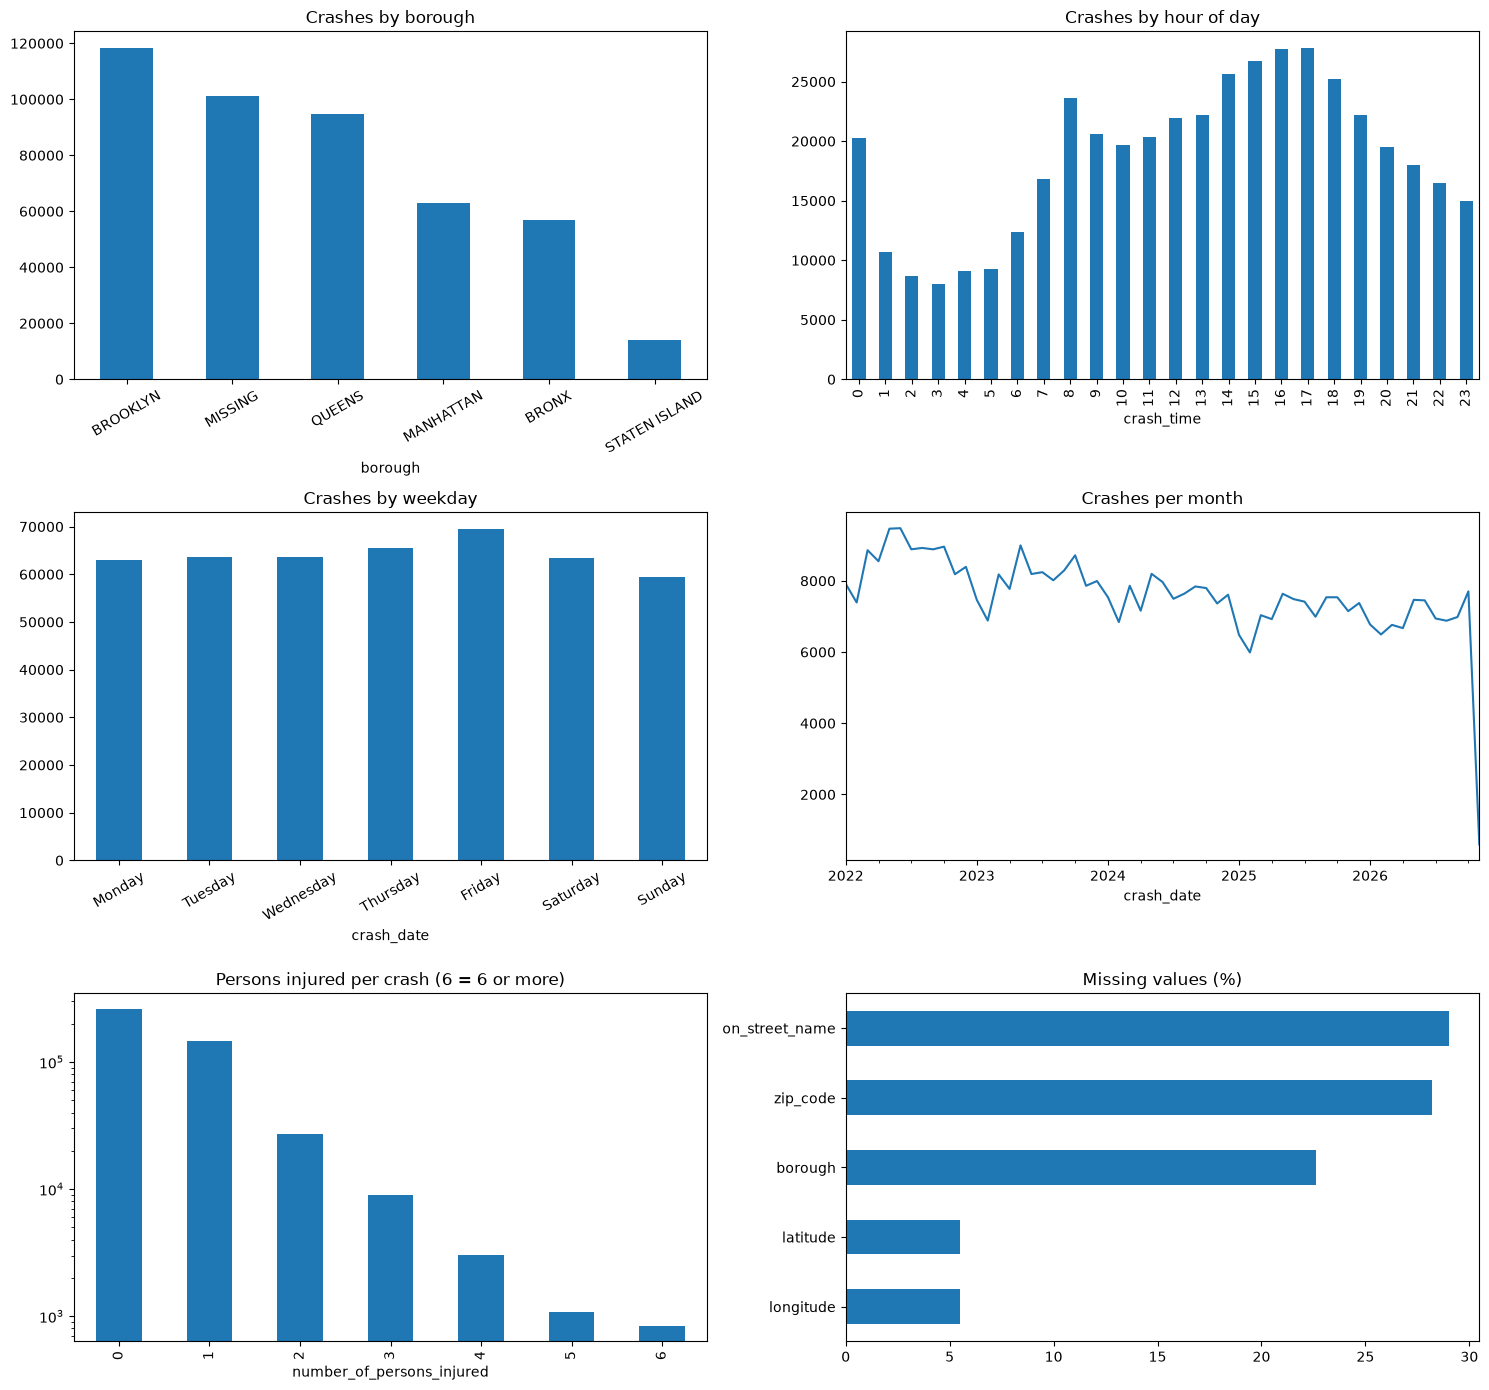

In [12]:
# 4c. EDA step 3: plots
hour = pd.to_datetime(df_transport_raw['crash_time'], format='%H:%M', errors='coerce').dt.hour
fig, ax = plt.subplots(3, 2, figsize=(15, 14))

df_transport_raw['borough'].fillna('MISSING').astype(str).str.upper().value_counts().plot.bar(ax=ax[0, 0], title='Crashes by borough', rot=30)

hour.value_counts().sort_index().plot.bar(ax=ax[0, 1], title='Crashes by hour of day')

dates.dt.day_name().value_counts().reindex(
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
).plot.bar(ax=ax[1, 0], title='Crashes by weekday', rot=30)

monthly = dates.dt.to_period('M').value_counts().sort_index()
monthly.index = monthly.index.to_timestamp()
monthly.plot(ax=ax[1, 1], title='Crashes per month')

nums['number_of_persons_injured'].clip(upper=6).value_counts().sort_index().plot.bar(
    ax=ax[2, 0], title='Persons injured per crash (6 = 6 or more)', logy=True)

miss = df_transport_raw.isna().mean().mul(100).sort_values(ascending=False)
miss[miss > 0].plot.barh(ax=ax[2, 1], title='Missing values (%)')
ax[2, 1].invert_yaxis()

plt.tight_layout()
plt.show()

### Plots (M2)
Brooklyn has the most crashes (about 118K) and Staten Island the fewest (about 14K); the 101,291 crashes with no borough would rank second. Crashes peak between 2 and 5 p.m., with a smaller spike at 8 a.m., and are fairly even across weekdays. Monthly crashes drift down from about 8K to 9K in 2022 to about 7K in 2025 to 2026, and about 250K of the 448K crashes injure nobody.

In [13]:
# 4d. CLEANING step 1: working copy, row log, duplicates guard, dates
CONTRACT_COLS_T = ['date', 'year', 'month', 'year_month', 'zip', 'borough', 'lat', 'lon',
                   'number_of_persons_injured', 'number_of_persons_killed',
                   'number_of_pedestrians_injured', 'number_of_pedestrians_killed',
                   'number_of_cyclist_injured', 'number_of_cyclist_killed',
                   'number_of_motorist_injured', 'number_of_motorist_killed']
steps_t = []
def log_t(step, d):
    steps_t.append((step, len(d)))

tr = df_transport_raw.copy()
log_t('raw download', tr)

tr = tr.drop_duplicates('collision_id')
log_t('repeated collision_id removed', tr)

tr = add_time_cols(tr, 'crash_date')
tr = tr.dropna(subset=['date'])
log_t('rows with unparseable date dropped', tr)

print(steps_t)
print(tr[['date', 'year', 'month', 'year_month']].head())
print(tr['year'].value_counts().sort_index())

[('raw download', 448091), ('repeated collision_id removed', 448091), ('rows with unparseable date dropped', 448091)]
        date  year  month year_month
0 2023-10-16  2023     10    2023-10
1 2024-11-01  2024     11    2024-11
2 2026-03-01  2026      3    2026-03
3 2023-09-18  2023      9    2023-09
4 2022-12-23  2022     12    2022-12
year
2022    103888
2023     96608
2024     91316
2025     85559
2026     70720
Name: count, dtype: int64


### Dates and duplicates (M2) 
`crash_date` was parsed with the shared `add_time_cols`, which created `year`, `month` and `year_month`. No dates failed and no `collision_id` was repeated, so no rows were removed; the check is kept so the cleaning still works if the data is downloaded again.

In [14]:
# 4e. CLEANING step 2: borough
before = tr['borough'].isna().sum()
tr['borough'] = clean_borough(tr['borough'])
print('Borough values:', tr['borough'].value_counts(dropna=False).to_dict())
print(f"Missing before: {before:,} | after clean_borough: {tr['borough'].isna().sum():,}")

Borough values: {'BROOKLYN': 118354, nan: 101291, 'QUEENS': 94825, 'MANHATTAN': 62998, 'BRONX': 56740, 'STATEN ISLAND': 13883}
Missing before: 101,291 | after clean_borough: 101,291


### Borough (M2)
Borough labels were standardised with the shared `clean_borough` (upper case, the five valid names only); no label was changed, and the 101,291 crashes without a borough stay missing. They are filled from the ZIP prefix in a later step, the same rule used in section 6.

In [15]:
# 4f. CLEANING step 3: coordinates
lat0 = pd.to_numeric(tr['latitude'], errors='coerce')
lon0 = pd.to_numeric(tr['longitude'], errors='coerce')
tr['lat'], tr['lon'] = clean_coords(lat0, lon0)
tr = tr.drop(columns=['latitude', 'longitude'])

n_missing = lat0.isna().sum()
n_zero = ((lat0 == 0) & (lon0 == 0)).sum()
n_invalid = tr['lat'].isna().sum()
print(f"Missing: {n_missing:,} | exactly 0,0: {n_zero:,} | other outside NYC box: {n_invalid - n_missing - n_zero:,}")
print(f"Coordinates now missing: {n_invalid:,} ({n_invalid / len(tr):.1%})")

Missing: 24,532 | exactly 0,0: 6,303 | other outside NYC box: 0
Coordinates now missing: 30,835 (6.9%)


### Coordinates (M2)
Latitude and longitude were checked with the shared `clean_coords` (NYC bounding box). 24,532 were missing and 6,303 sat at the 0,0 placeholder; none fell outside the box otherwise, so 30,835 crashes (6.9%) have no usable coordinates. We kept these rows rather than dropping them: 21,465 of them also have no ZIP (from the EDA), but the other 9,370 still have one. They only cannot be used to recover a missing ZIP.

In [16]:
# 4g. CLEANING step 4a: how accurate is "nearest crash within 0.5 km" at recovering a ZIP?
tr['zip'] = clean_zip(tr['zip_code'])

known = tr.dropna(subset=['zip', 'lat', 'lon'])
test = known.sample(20_000, random_state=1)
ref_t = known.drop(test.index)

tree = BallTree(np.radians(ref_t[['lat', 'lon']].to_numpy()), metric='haversine')
dist, idx = tree.query(np.radians(test[['lat', 'lon']].to_numpy()), k=1)
within = dist[:, 0] * 6371.0088 <= 0.5
pred = ref_t['zip'].to_numpy()[idx[:, 0]]

print(f"Test sample: {len(test):,} crashes with a known ZIP")
print(f"Nearest other crash within 0.5 km: {within.mean():.1%}")
print(f"Recovered ZIP equals the true ZIP (where within 0.5 km): {(pred[within] == test['zip'].to_numpy()[within]).mean():.1%}")

Test sample: 20,000 crashes with a known ZIP
Nearest other crash within 0.5 km: 100.0%
Recovered ZIP equals the true ZIP (where within 0.5 km): 99.1%


### Testing the ZIP recovery (M2)
To check the method, we hid the ZIP of 20,000 crashes that have one and recovered it from the nearest other crash within 0.5 km. The recovered ZIP matched the true one in 99.1% of cases. This test used crashes that already had a ZIP, so it may overstate the accuracy for crashes that really lack one.

In [17]:
# 4h. CLEANING step 4b: recover missing ZIPs from coordinates, drop the rest
tr = tr.drop(columns=['zip_code'])
missing_before = tr['zip'].isna().sum()

tr = fill_zip_nearest(tr, tr, max_km=0.5)
missing_after = tr['zip'].isna().sum()

print(f"ZIP missing before: {missing_before:,}")
print(f"Recovered from coordinates: {missing_before - missing_after:,}")
print(f"Still missing: {missing_after:,}")
print(f"  no valid coordinates : {(tr['zip'].isna() & tr['lat'].isna()).sum():,}")
print(f"  coordinates but no crash with a ZIP within 0.5 km: {(tr['zip'].isna() & tr['lat'].notna()).sum():,}")

tr = tr.dropna(subset=['zip'])
log_t('rows with no ZIP after recovery dropped', tr)
print(f"Kept {len(tr):,} of {len(df_transport_raw):,} ({len(tr) / len(df_transport_raw):.1%})")

ZIP missing before: 126,732
Recovered from coordinates: 99,144
Still missing: 27,588
  no valid coordinates : 21,465
  coordinates but no crash with a ZIP within 0.5 km: 6,123
Kept 420,503 of 448,091 (93.8%)


### ZIP (M2).
The shared `clean_zip` kept 5-digit NYC ZIPs only. Of 126,732 crashes without a valid ZIP, 99,144 were recovered with `fill_zip_nearest` (nearest crash with a ZIP within 0.5 km). We recover instead of dropping because crashes without a ZIP are more severe (see the EDA). The remaining 27,588 were dropped because ZIP is the join key: 21,465 have no coordinates and 6,123 have no crash with a ZIP within 0.5 km. This keeps 420,503 of 448,091 crashes (93.8%). Limitation: recovered ZIPs are borrowed from other crashes, so a crash near a ZIP boundary can land in the neighbouring ZIP.

In [18]:
# 4i. CLEANING step 5a: do ZIPs and borough labels agree?
ZIP_PREFIX_T = {'100': 'MANHATTAN', '101': 'MANHATTAN', '102': 'MANHATTAN', '103': 'STATEN ISLAND',
                '104': 'BRONX', '110': 'QUEENS', '111': 'QUEENS', '112': 'BROOKLYN',
                '113': 'QUEENS', '114': 'QUEENS', '116': 'QUEENS'}
QUEENS_110 = ['11004', '11005']    # the only 110xx ZIPs inside NYC; the rest of 110xx is Nassau County

def zip_to_borough(z):
    b = z.str[:3].map(ZIP_PREFIX_T)
    return b.where(~(z.str.startswith('110') & ~z.isin(QUEENS_110)))

tr['borough_from_zip'] = zip_to_borough(tr['zip'])
has_label = tr['borough'].notna()

print(f"ZIPs whose prefix is not a NYC borough prefix: {tr['borough_from_zip'].isna().sum():,}")
print(tr.loc[tr['borough_from_zip'].isna(), 'zip'].value_counts().head(10))
print()
print(f"Crashes with a borough label: {has_label.sum():,}")
agree = tr.loc[has_label, 'borough'] == tr.loc[has_label, 'borough_from_zip']
print(f"  label agrees with the ZIP-prefix borough: {agree.sum():,} ({agree.mean():.2%})")
print(tr.loc[has_label].loc[~agree].groupby(['borough', 'borough_from_zip'], dropna=False).size())
print()
print(f"Crashes without a label that the ZIP can fill: {(~has_label & tr['borough_from_zip'].notna()).sum():,}")

ZIPs whose prefix is not a NYC borough prefix: 240
zip
11001    129
11040    111
Name: count, dtype: int64

Crashes with a borough label: 345,386
  label agrees with the ZIP-prefix borough: 344,969 (99.88%)
borough    borough_from_zip
BRONX      MANHATTAN            24
BROOKLYN   QUEENS               42
MANHATTAN  BRONX                 3
QUEENS     BROOKLYN            117
           MANHATTAN            10
           NaN                 221
dtype: int64

Crashes without a label that the ZIP can fill: 75,098


### Borough versus ZIP (M2).
Of the 345,386 crashes that have both a borough label and a ZIP, 99.88% (344,969) agree with the borough implied by the ZIP prefix, so the prefix is reliable for filling the missing boroughs. 417 crashes disagree: 196 point to a different NYC borough, and 221 have a Queens label but a ZIP outside the NYC prefix list (11001 or 11040; 240 crashes in total have one of these two ZIPs).

In [19]:
# 4j. CLEANING step 5b: borough from ZIP prefix; drop non-NYC ZIPs and contradictions
non_nyc = tr['borough_from_zip'].isna()
print(f"ZIP outside the NYC prefixes (11001, 11040): {non_nyc.sum():,} crashes dropped")
tr = tr[~non_nyc]
log_t('rows with a ZIP outside the NYC prefixes dropped', tr)

clash = tr['borough'].notna() & (tr['borough'] != tr['borough_from_zip'])
print(f"Borough label contradicts the ZIP: {clash.sum():,} crashes dropped")
tr = tr[~clash]
log_t('rows where the borough label contradicts the ZIP dropped', tr)

filled = tr['borough'].isna().sum()
tr['borough'] = tr['borough'].fillna(tr['borough_from_zip'])
tr = tr.drop(columns=['borough_from_zip'])
print(f"Borough filled from the ZIP prefix: {filled:,} | borough missing now: {tr['borough'].isna().sum():,}")
print(tr['borough'].value_counts())
print(f"Kept {len(tr):,} of {len(df_transport_raw):,} ({len(tr) / len(df_transport_raw):.1%})")

ZIP outside the NYC prefixes (11001, 11040): 240 crashes dropped
Borough label contradicts the ZIP: 196 crashes dropped
Borough filled from the ZIP prefix: 75,098 | borough missing now: 0
borough
BROOKLYN         141205
QUEENS           119157
MANHATTAN         74143
BRONX             68657
STATEN ISLAND     16905
Name: count, dtype: int64
Kept 420,067 of 448,091 (93.7%)


### Borough from ZIP (M2)
240 crashes with ZIP 11001 or 11040 (outside the NYC prefixes) and 196 whose borough label contradicts their ZIP were dropped, about 0.1% of the table; the ZIP is the join key, so a crash we cannot place reliably is not worth keeping. The 75,098 crashes without a borough were then filled from the ZIP prefix, which agreed with the label in 99.88% of labelled crashes, so no borough is missing. After the ZIP and borough steps 420,067 of 448,091 crashes remain (93.7%).

In [20]:
# 4k. CLEANING step 6: outliers in the injury and fatality counts
for col in ['number_of_persons_injured', 'number_of_persons_killed']:
    lo, hi = iqr_bounds(tr[col])
    n_out = (tr[col] > hi).sum()
    print(f"{col}: IQR fences {lo:.1f} to {hi:.1f} -> {n_out:,} crashes above ({n_out / len(tr):.1%})")

inj_parts = tr[['number_of_pedestrians_injured', 'number_of_cyclist_injured', 'number_of_motorist_injured']].sum(axis=1)
print(f"\nInjured total > sum of the three groups: {(tr['number_of_persons_injured'] > inj_parts).sum():,}")
print(f"Crashes with 10 or more injured: {(tr['number_of_persons_injured'] >= 10).sum():,}")
print('\nLargest crashes by persons injured:')
print(tr.nlargest(5, 'number_of_persons_injured')[['date', 'borough', 'zip', 'number_of_persons_injured',
                                                    'number_of_pedestrians_injured', 'number_of_cyclist_injured',
                                                    'number_of_motorist_injured']].to_string(index=False))

number_of_persons_injured: IQR fences -1.5 to 2.5 -> 12,797 crashes above (3.0%)
number_of_persons_killed: IQR fences 0.0 to 0.0 -> 1,077 crashes above (0.3%)

Injured total > sum of the three groups: 11,942
Crashes with 10 or more injured: 90

Largest crashes by persons injured:
      date       borough   zip  number_of_persons_injured  number_of_pedestrians_injured  number_of_cyclist_injured  number_of_motorist_injured
2023-04-07        QUEENS 11361                         34                              0                          0                          34
2023-12-28 STATEN ISLAND 10306                         25                              0                          0                          25
2023-03-17        QUEENS 11428                         23                              0                          0                          23
2026-08-18         BRONX 10459                         22                              0                          0                          22

### Outliers (M2)
No injury or fatality counts were removed. The IQR rule does not fit them: with a median of 0, its upper fence is 2.5 injured, which flags 12,797 crashes (3.0%), and for deaths the fence is 0, which flags all 1,077 fatal crashes (0.3%). The largest crash has 34 injured, all counted as motorists, and 90 crashes have 10 or more; for the five largest, the group counts add up to the total, so nothing marks them as errors. In 11,942 crashes the injured total is higher than the pedestrian, cyclist and motorist counts combined, so those three groups do not cover every injured person; we keep the published total.

In [21]:
# 4l. CLEANING step 7: final tables, checks, row funnel
df_transport_full = tr.reset_index(drop=True)
df_transport = df_transport_full[CONTRACT_COLS_T].copy()

KEY_T = ['date', 'year', 'month', 'year_month', 'zip', 'borough']
COUNTS_T = CONTRACT_COLS_T[8:]
assert list(df_transport.columns) == CONTRACT_COLS_T, 'columns differ from contract'
assert df_transport[KEY_T + COUNTS_T].isna().sum().sum() == 0, 'nulls in key or count columns'
assert df_transport['zip'].str.fullmatch(r'\d{5}').all(), 'ZIP is not 5 digits'
assert set(df_transport['borough']) <= set(BOROUGHS), 'unexpected borough'
assert (df_transport[COUNTS_T] >= 0).all().all(), 'negative counts'
assert not df_transport_full['collision_id'].duplicated().any(), 'duplicate collisions remain'

print('All checks passed')
print('Rows kept:', f"{len(df_transport):,}", 'of', f"{len(df_transport_raw):,}")
print('Distinct ZIPs:', df_transport['zip'].nunique())
print(df_transport.groupby('borough')['zip'].nunique())
print('Rows with no coordinates (lat/lon missing):', f"{df_transport['lat'].isna().sum():,}")

funnel_t = pd.DataFrame(steps_t, columns=['step', 'rows'])
funnel_t['removed'] = (-funnel_t['rows'].diff()).fillna(0).astype(int)
display(funnel_t)

All checks passed
Rows kept: 420,067 of 448,091
Distinct ZIPs: 226
borough
BRONX            25
BROOKLYN         39
MANHATTAN        87
QUEENS           64
STATEN ISLAND    11
Name: zip, dtype: int64
Rows with no coordinates (lat/lon missing): 9,355


,step,rows,removed
0,raw download,448091,0
1,repeated collision_id removed,448091,0
2,rows with unparseable date dropped,448091,0
3,rows with no ZIP after recovery dropped,420503,27588
4,rows with a ZIP outside the NYC prefixes dropped,420263,240
5,rows where the borough label contradicts the Z...,420067,196


### Result (M2)
420,067 of 448,091 crashes (93.7%) were kept. The 28,024 removed are 27,588 with no ZIP after recovery, 240 with a ZIP outside NYC and 196 whose borough label contradicted the ZIP. The table covers 226 ZIPs (Manhattan 87, Queens 64, Brooklyn 39, Bronx 25, Staten Island 11) and has no missing values in the date, ZIP, borough or count columns; 9,355 rows have a ZIP but no coordinates. `df_transport` holds exactly the agreed columns, and `df_transport_full` keeps the extras (`collision_id`, `crash_time`, `on_street_name`) for our own analysis.

## 5. INTEGRATION (**M3**)
### 5a. Quick-clean stand-ins
These give a first working `merged_data.csv` today, so the website can be built on real data while M1 and M2 do their full cleaning.

In [22]:
def quick_clean_transport(raw):
    """Minimal standardisation so integration can run NOW. M2 replaces this with the full cleaning
    (EDA, outliers, justified decisions) as long as the OUTPUT COLUMNS stay the same."""
    d = raw.copy()
    n0 = len(d)
    if 'collision_id' in d:
        d = d.drop_duplicates('collision_id')
    d = add_time_cols(d, 'crash_date')
    out = pd.DataFrame(index=d.index)
    out['date'], out['year'], out['month'], out['year_month'] = d['date'], d['year'], d['month'], d['year_month']
    out['zip'] = clean_zip(d['zip_code'])
    out['borough'] = clean_borough(d['borough'])
    out['lat'], out['lon'] = clean_coords(d['latitude'], d['longitude'])
    for c in ['number_of_persons_injured', 'number_of_persons_killed',
              'number_of_pedestrians_injured', 'number_of_pedestrians_killed',
              'number_of_cyclist_injured', 'number_of_cyclist_killed',
              'number_of_motorist_injured', 'number_of_motorist_killed']:
        out[c] = pd.to_numeric(d[c], errors='coerce').fillna(0) if c in d else 0
    missing_before = out['zip'].isna().sum()
    out = fill_zip_nearest(out, out)                       # recover ZIP from the nearest crash that has one
    print(f'[transport] rows {n0:,} -> {len(d):,} after dedupe | ZIP missing {missing_before:,} -> {out["zip"].isna().sum():,} after coordinate recovery')
    out = out.dropna(subset=['date', 'zip'])
    print(f'[transport] kept {len(out):,} rows with valid date + ZIP')
    return out

def quick_clean_housing(raw, zip_reference=None):
    """Minimal standardisation. M1 replaces it with the full cleaning (same output columns).
    zip_reference: cleaned transport table, used to recover ZIPs if the housing table lacks them."""
    cols = raw.columns
    date_col = find_col(cols, ['filing_date', 'filed_date'], regex=r'filing.*date|date.*filing')
    type_col = find_col(cols, ['job_type'], regex=r'job.*type')
    zip_col  = find_col(cols, ['zip_code', 'zip', 'zipcode'], regex=r'^zip', required=False)
    lat_col  = find_col(cols, ['latitude', 'gis_latitude'], regex=r'^(gis_)?lat', required=False)
    lon_col  = find_col(cols, ['longitude', 'gis_longitude'], regex=r'^(gis_)?lon', required=False)
    id_col   = find_col(cols, ['job_filing_number'], required=False)
    d = raw.copy()
    n0 = len(d)
    if id_col:
        d = d.drop_duplicates(id_col)
    d = add_time_cols(d, date_col)
    out = pd.DataFrame(index=d.index)
    out['date'], out['year'], out['month'], out['year_month'] = d['date'], d['year'], d['month'], d['year_month']
    out['job_type'] = d[type_col]
    out['zip'] = clean_zip(d[zip_col]) if zip_col else np.nan
    out['borough'] = clean_borough(d['borough']) if 'borough' in d else np.nan
    if lat_col and lon_col:
        out['lat'], out['lon'] = clean_coords(d[lat_col], d[lon_col])
    else:
        out['lat'], out['lon'] = np.nan, np.nan
    missing_before = out['zip'].isna().sum()
    if zip_reference is not None:
        out = fill_zip_nearest(out, zip_reference)
    print(f'[housing] rows {n0:,} -> {len(d):,} after dedupe | ZIP column found: {bool(zip_col)} | '
          f'ZIP missing {missing_before:,} -> {out["zip"].isna().sum():,} after recovery')
    out = out.dropna(subset=['date', 'zip'])
    print(f'[housing] kept {len(out):,} rows with valid date + ZIP')
    return out

In [23]:
df_transport_q = quick_clean_transport(df_transport_raw)
df_housing_q   = quick_clean_housing(df_housing_raw, zip_reference=df_transport_q)

# Flip to True once M1 and M2 have delivered their full cleaning (same columns, see the contract above)
USE_FULL_CLEANING = False
housing_for_join   = df_housing   if USE_FULL_CLEANING else df_housing_q
transport_for_join = df_transport if USE_FULL_CLEANING else df_transport_q

[transport] rows 448,091 -> 448,091 after dedupe | ZIP missing 126,732 -> 27,588 after coordinate recovery
[transport] kept 420,503 rows with valid date + ZIP
[housing] rows 733,283 -> 730,103 after dedupe | ZIP column found: True | ZIP missing 161,601 -> 2,017 after recovery
[housing] kept 728,086 rows with valid date + ZIP


### 5b. Aggregate and join at ZIP x month

In [24]:
SCHEMA_COLS = ['zip', 'borough', 'year', 'month', 'year_month', 'lat', 'lon',
               'filings_new_building', 'filings_alteration', 'filings_other',
               'crashes_total', 'crashes_pedestrian', 'crashes_cyclist', 'crashes_motorist',
               'injuries', 'fatalities']

def housing_group(job_type):
    t = job_type.astype(str).str.strip().str.lower()
    is_nb  = t.str.contains('new building') | t.eq('nb')
    is_alt = t.str.contains('alteration') | t.str.fullmatch(r'a[123]')
    return np.select([is_nb, is_alt], ['new_building', 'alteration'], default='other')

def aggregate_housing(h):
    """One row per ZIP x month: number of job filings by group."""
    h = h.assign(job_group=housing_group(h['job_type']))
    g = h.groupby(['zip', 'year_month', 'job_group']).size().unstack('job_group', fill_value=0)
    for c in ['new_building', 'alteration', 'other']:
        if c not in g:
            g[c] = 0
    return g[['new_building', 'alteration', 'other']].add_prefix('filings_').reset_index()

def aggregate_transport(t):
    """One row per ZIP x month: crashes (all / with pedestrian / cyclist / motorist casualties), injuries, deaths."""
    t = t.assign(
        ped=(t['number_of_pedestrians_injured'] + t['number_of_pedestrians_killed']) > 0,
        cyc=(t['number_of_cyclist_injured'] + t['number_of_cyclist_killed']) > 0,
        mot=(t['number_of_motorist_injured'] + t['number_of_motorist_killed']) > 0)
    return (t.groupby(['zip', 'year_month'])
              .agg(crashes_total=('ped', 'size'), crashes_pedestrian=('ped', 'sum'),
                   crashes_cyclist=('cyc', 'sum'), crashes_motorist=('mot', 'sum'),
                   injuries=('number_of_persons_injured', 'sum'),
                   fatalities=('number_of_persons_killed', 'sum')).reset_index())

def build_zip_month_table(housing, transport):
    """Integrate at ZIP x month. Decisions (justify in the markdown cell below):
       1. keep only ZIPs present in BOTH datasets (a ZIP seen on one side only gives no comparison)
       2. use the common date window and drop the last month if it is incomplete
       3. build a COMPLETE ZIP x month grid so 'no filings / no crashes' is an explicit 0, not a missing row"""
    zips = sorted(set(housing['zip']) & set(transport['zip']))
    h, t = housing[housing['zip'].isin(zips)], transport[transport['zip'].isin(zips)]
    start = max(h['date'].min(), t['date'].min()).to_period('M')
    end_date = min(h['date'].max(), t['date'].max())
    end = end_date.to_period('M')
    if end_date.normalize() < end.end_time.normalize():     # last month not finished -> drop it
        end = end - 1
    months = [str(p) for p in pd.period_range(start, end, freq='M')]
    h, t = h[h['year_month'].isin(months)], t[t['year_month'].isin(months)]

    grid = pd.MultiIndex.from_product([zips, months], names=['zip', 'year_month']).to_frame(index=False)
    merged = (grid.merge(aggregate_housing(h), on=['zip', 'year_month'], how='left')
                  .merge(aggregate_transport(t), on=['zip', 'year_month'], how='left'))

    # ZIP-level attributes: borough = most common borough label, lat/lon = centroid of all point records
    pts = pd.concat([h[['zip', 'borough', 'lat', 'lon']], t[['zip', 'borough', 'lat', 'lon']]])
    zip_info = pts.groupby('zip').agg(
        borough=('borough', lambda s: s.mode().iloc[0] if s.notna().any() else np.nan),
        lat=('lat', 'mean'), lon=('lon', 'mean')).reset_index()
    merged = merged.merge(zip_info, on='zip', how='left')
    merged['year'] = merged['year_month'].str[:4].astype(int)
    merged['month'] = merged['year_month'].str[5:7].astype(int)

    info = dict(zips_housing=housing['zip'].nunique(), zips_transport=transport['zip'].nunique(),
                zips_kept=len(zips), window=f'{months[0]} to {months[-1]}', months=len(months),
                grid_rows=len(grid), housing_rows_used=len(h), transport_rows_used=len(t))
    return merged, info

In [25]:
merged, info = build_zip_month_table(housing_for_join, transport_for_join)
print(info)
merged.head()

{'zips_housing': 370, 'zips_transport': 228, 'zips_kept': 217, 'window': '2022-01 to 2026-10', 'months': 58, 'grid_rows': 12586, 'housing_rows_used': 657136, 'transport_rows_used': 419912}


,zip,year_month,filings_new_building,filings_alteration,filings_other,crashes_total,crashes_pedestrian,crashes_cyclist,crashes_motorist,injuries,fatalities,borough,lat,lon,year,month
0,10001,2022-01,54.0,596.0,4.0,31.0,3.0,2.0,2.0,9.0,0.0,MANHATTAN,40.740851,-73.966274,2022,1
1,10001,2022-02,40.0,568.0,7.0,38.0,8.0,2.0,4.0,18.0,0.0,MANHATTAN,40.740851,-73.966274,2022,2
2,10001,2022-03,39.0,862.0,18.0,55.0,7.0,3.0,8.0,22.0,0.0,MANHATTAN,40.740851,-73.966274,2022,3
3,10001,2022-04,60.0,706.0,17.0,52.0,7.0,8.0,5.0,20.0,0.0,MANHATTAN,40.740851,-73.966274,2022,4
4,10001,2022-05,41.0,795.0,24.0,56.0,10.0,8.0,4.0,24.0,0.0,MANHATTAN,40.740851,-73.966274,2022,5


**Justification (M3: replace the numbers with `info` from your run)**
- **Join key `zip` + `year_month`.** Individual filings and crashes do not correspond to each other, so we compare *activity levels* per neighbourhood-month. ZIP is available on both sides (or recoverable from coordinates) and gives 217 ZIP codes, far more than the 5 boroughs; month keeps seasonality and allows lag analysis.
- **Alternatives considered:** borough x month (only 5 units, hides local patterns); row-level spatial join (a filing has no matching crash row, so it would be meaningless); census tract (too sparse per month).
- **Only ZIPs present in both datasets are kept** (a ZIP seen on one side gives no comparison).
- **Common window, partial last month dropped** (the crash feed ends earlier than the housing feed).
- **Complete ZIP x month grid:** months with no filings or no crashes are real zeros, so they are kept as explicit 0 rows instead of missing.
- **ZIP recovery:** missing crash ZIPs are filled from the nearest crash that has one (<= 0.5 km). If the housing table has no ZIP, it is filled from the nearest crash point: this borrows the crash table's ZIP boundaries, which we list as a limitation.

In [26]:
from IPython.display import Markdown, display
display(Markdown(f"""**Result of the integration:** {info['zips_kept']} ZIP codes appear in both datasets (housing had {info['zips_housing']} ZIPs, crashes had {info['zips_transport']}), \
over {info['months']} months ({info['window']}), giving a complete grid of {info['grid_rows']:,} ZIP-month rows. \
{info['housing_rows_used']:,} housing filings and {info['transport_rows_used']:,} crashes fall inside that grid."""))

**Result of the integration:** 217 ZIP codes appear in both datasets (housing had 370 ZIPs, crashes had 228), over 58 months (2022-01 to 2026-10), giving a complete grid of 12,586 ZIP-month rows. 657,136 housing filings and 419,912 crashes fall inside that grid.

## 6. POST-INTEGRATION CLEANING (**M3**) (required)

In [27]:
COUNT_COLS = ['filings_new_building', 'filings_alteration', 'filings_other',
              'crashes_total', 'crashes_pedestrian', 'crashes_cyclist', 'crashes_motorist',
              'injuries', 'fatalities']

# The first 3 digits of a NYC ZIP identify the borough reliably, so we use them to catch wrong borough labels
ZIP_PREFIX_BOROUGH = {'100': 'MANHATTAN', '101': 'MANHATTAN', '102': 'MANHATTAN', '103': 'STATEN ISLAND',
                      '104': 'BRONX', '110': 'QUEENS', '111': 'QUEENS', '112': 'BROOKLYN',
                      '113': 'QUEENS', '114': 'QUEENS', '116': 'QUEENS'}

def fix_borough_by_zip(m):
    """Inconsistency check: where the borough label disagrees with the ZIP prefix, trust the ZIP."""
    m = m.copy()
    expected = m['zip'].str[:3].map(ZIP_PREFIX_BOROUGH)
    wrong = expected.notna() & (expected != m['borough'])
    if wrong.any():
        fixes = (m.loc[wrong, ['zip', 'borough']].drop_duplicates('zip').assign(corrected_to=expected[wrong]))
        print(f'Borough corrected from ZIP prefix for {fixes.shape[0]} ZIPs:'); print(fixes.to_string(index=False))
    m.loc[wrong, 'borough'] = expected[wrong]
    return m

def post_integration_clean(merged):
    """1) NaN from the left joins = no activity -> 0   2) fix dtypes   3) drop rows with no borough/coords
       4) remove duplicates   5) fix borough labels that contradict the ZIP   6) enforce the agreed schema/column order"""
    m = merged.copy()
    n0 = len(m)
    print('NaNs per column BEFORE:\n', m.isna().sum()[lambda s: s > 0].to_string())
    m[COUNT_COLS] = m[COUNT_COLS].fillna(0).astype(int)
    m['zip'] = m['zip'].astype(str).str.zfill(5)
    m = m.dropna(subset=['borough', 'lat', 'lon']).drop_duplicates(['zip', 'year_month'])
    m = fix_borough_by_zip(m)
    print(f'rows {n0:,} -> {len(m):,} (dropped rows without borough/coordinates, and duplicates)')
    return m[SCHEMA_COLS].sort_values(['zip', 'year_month']).reset_index(drop=True)

def validate(m):
    """Fail loudly if the table breaks the contract that the website and teammates rely on."""
    assert list(m.columns) == SCHEMA_COLS, 'columns differ from the schema contract'
    assert m.isna().sum().sum() == 0, 'nulls remain'
    assert not m.duplicated(['zip', 'year_month']).any(), 'duplicate ZIP-months'
    assert (m[COUNT_COLS] >= 0).all().all(), 'negative counts'
    assert (m['crashes_pedestrian'] <= m['crashes_total']).all(), 'pedestrian crashes exceed total'
    assert set(m['borough']) <= set(BOROUGHS), 'unexpected borough labels'
    print('VALID:', m.shape, '|', m['zip'].nunique(), 'ZIPs x', m['year_month'].nunique(), 'months')

def outlier_report(m, cols=('filings_new_building', 'crashes_total')):
    """IQR rule per ZIP total. Outliers are REPORTED, not removed: they are real high-activity ZIPs."""
    tot = m.groupby('zip')[list(cols)].sum()
    for c in cols:
        q1, q3 = tot[c].quantile([.25, .75]); hi = q3 + 1.5 * (q3 - q1)
        print(f'{c}: IQR upper bound {hi:,.0f} -> {(tot[c] > hi).sum()} ZIPs above it')

In [28]:
final = post_integration_clean(merged)     # new NaNs from the joins -> 0, dtypes, redundant rows, schema order
validate(final)                            # fails loudly if the contract is broken
outlier_report(final)
final.describe().T

NaNs per column BEFORE:
 filings_new_building    1083
filings_alteration      1083
filings_other           1083
crashes_total           1955
crashes_pedestrian      1955
crashes_cyclist         1955
crashes_motorist        1955
injuries                1955
fatalities              1955
Borough corrected from ZIP prefix for 4 ZIPs:
  zip   borough corrected_to
10044     BRONX    MANHATTAN
10105  BROOKLYN    MANHATTAN
11109 MANHATTAN       QUEENS
11423 MANHATTAN       QUEENS
rows 12,586 -> 12,586 (dropped rows without borough/coordinates, and duplicates)
VALID: (12586, 16) | 217 ZIPs x 58 months
filings_new_building: IQR upper bound 614 -> 28 ZIPs above it
crashes_total: IQR upper bound 6,489 -> 1 ZIPs above it


,count,mean,std,min,25%,50%,75%,max
year,12586.0,2023.931034,1.387959,2022.000000,2023.000000,2024.000000,2025.000000,2026.000000
month,12586.0,6.327586,3.380544,1.000000,3.000000,6.000000,9.000000,12.000000
lat,12586.0,40.730898,0.065631,40.560958,40.694973,40.734278,40.761428,40.886483
lon,12586.0,-73.927363,0.075842,-74.159417,-73.972869,-73.940407,-73.882151,-73.734925
filings_new_building,12586.0,5.177499,12.675672,0.000000,0.000000,1.000000,5.000000,329.000000
filings_alteration,12586.0,45.627682,79.173182,0.000000,8.000000,22.000000,52.000000,906.000000
filings_other,12586.0,1.406483,4.213968,0.000000,0.000000,0.000000,1.000000,58.000000
crashes_total,12586.0,33.363420,28.249838,0.000000,9.000000,30.000000,51.000000,211.000000
crashes_pedestrian,12586.0,3.277133,3.458401,0.000000,0.000000,2.000000,5.000000,25.000000
crashes_cyclist,12586.0,1.800493,2.425072,0.000000,0.000000,1.000000,3.000000,18.000000


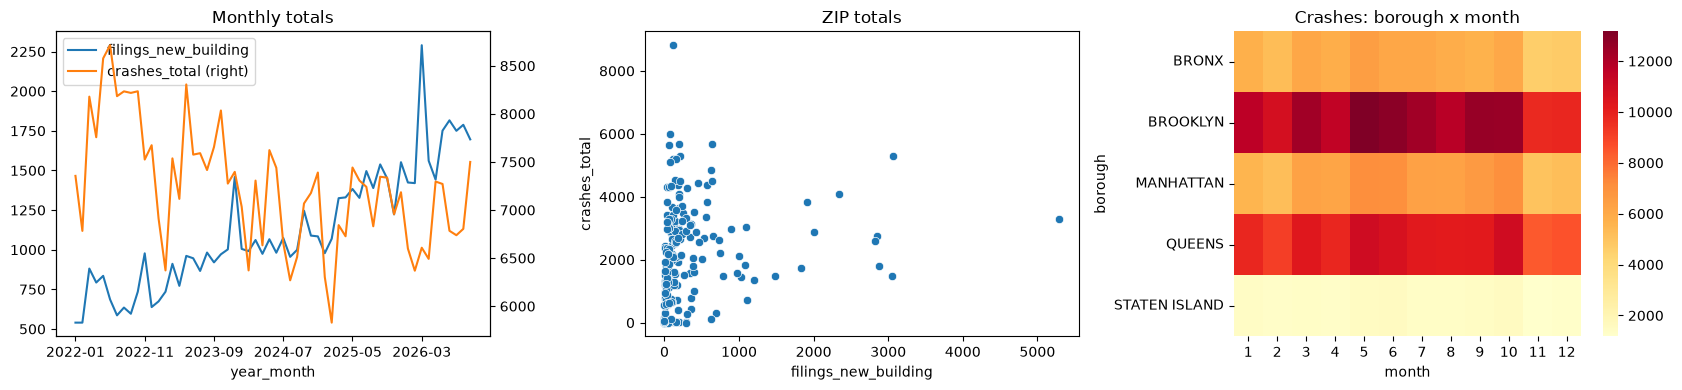

In [29]:
# Sanity plots: do the integrated numbers look believable?
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
final.groupby('year_month')[['filings_new_building', 'crashes_total']].sum().plot(ax=ax[0], secondary_y='crashes_total', title='Monthly totals')
z = final.groupby('zip')[['filings_new_building', 'crashes_total']].sum()
sns.scatterplot(data=z, x='filings_new_building', y='crashes_total', ax=ax[1]); ax[1].set_title('ZIP totals')
sns.heatmap(final.pivot_table(index='borough', columns='month', values='crashes_total', aggfunc='sum'), ax=ax[2], cmap='YlOrRd')
ax[2].set_title('Crashes: borough x month')
plt.tight_layout(); plt.show()

In [30]:
# Export: THIS file is what the website reads (put it in the repo at data/merged_data.csv)
final.to_csv('merged_data.csv', index=False)
try:
    from google.colab import files
    files.download('merged_data.csv')
except ImportError:
    pass
print(final.shape)

(12586, 16)


### 6b. Data health check (M3): numbers to quote in section 1 and the justification

In [31]:
def health_report(final, housing_raw, transport_raw, housing_used, transport_used, info):
    """Numbers to quote in section 1 and the justification: row funnel, date windows, zeros, ZIP coverage."""
    print('--- ROW FUNNEL (how many records survived each step) ---')
    print(f"housing  : raw {len(housing_raw):,} -> cleaned {len(housing_used):,} -> inside window {info['housing_rows_used']:,}")
    print(f"transport: raw {len(transport_raw):,} -> cleaned {len(transport_used):,} -> inside window {info['transport_rows_used']:,}")
    print('\n--- DATE WINDOWS ---')
    print('housing  latest date :', housing_used['date'].max().date())
    print('crashes  latest date :', transport_used['date'].max().date(), '<- the crash feed may stop earlier than housing')
    print('integrated window    :', info['window'], f"({info['months']} months)")
    print('\n--- ZIP COVERAGE ---')
    print(f"ZIPs in housing {info['zips_housing']}, in crashes {info['zips_transport']}, kept (in both) {info['zips_kept']}")
    print(final.groupby('borough')['zip'].nunique().rename('ZIPs per borough').to_string())
    print('\n--- SHARE OF ZIP-MONTHS WITH ZERO ACTIVITY (quote this in your limitations) ---')
    for c in ['filings_new_building', 'filings_alteration', 'crashes_total', 'crashes_pedestrian', 'crashes_cyclist']:
        print(f'{c:24s} {(final[c] == 0).mean():6.1%}')
    print('\n--- TOTALS ---')
    print(final[['filings_new_building', 'filings_alteration', 'filings_other', 'crashes_total', 'injuries', 'fatalities']].sum().to_string())

health_report(final, df_housing_raw, df_transport_raw, housing_for_join, transport_for_join, info)

--- ROW FUNNEL (how many records survived each step) ---
housing  : raw 733,283 -> cleaned 728,086 -> inside window 657,136
transport: raw 448,091 -> cleaned 420,503 -> inside window 419,912

--- DATE WINDOWS ---
housing  latest date : 2026-11-05
crashes  latest date : 2026-11-03 <- the crash feed may stop earlier than housing
integrated window    : 2022-01 to 2026-10 (58 months)

--- ZIP COVERAGE ---
ZIPs in housing 370, in crashes 228, kept (in both) 217
borough
BRONX            25
BROOKLYN         39
MANHATTAN        78
QUEENS           64
STATEN ISLAND    11

--- SHARE OF ZIP-MONTHS WITH ZERO ACTIVITY (quote this in your limitations) ---
filings_new_building      45.8%
filings_alteration         9.0%
crashes_total             15.5%
crashes_pedestrian        28.6%
crashes_cyclist           43.6%

--- TOTALS ---
filings_new_building     65164
filings_alteration      574270
filings_other            17702
crashes_total           419912
injuries                234945
fatalities         

In [32]:
from IPython.display import Markdown, display
# Every number below is computed from the data, so it stays correct if M1/M2 later change the cleaning.
n_t = df_transport_raw.drop_duplicates('collision_id').shape[0] if 'collision_id' in df_transport_raw else len(df_transport_raw)
n_h = df_housing_raw.drop_duplicates('job_filing_number').shape[0] if 'job_filing_number' in df_housing_raw else len(df_housing_raw)
unplaced_t = 1 - len(transport_for_join) / n_t
unplaced_h = 1 - len(housing_for_join) / n_h
yr = final.groupby('year')[['filings_new_building', 'filings_alteration']].sum()
full = yr.loc[2022:2025]
display(Markdown(f"""**Limitations of the integrated data (M3)**
- The crash feed was reported paused in 2026; the latest crash record in our download is from {transport_for_join['date'].max():%B %Y}, and the integrated window is {info['window']}.
- Filings are applications, not buildings finished or work started; timing can differ by months.
- {unplaced_t:.0%} of crash records and {unplaced_h:.0%} of housing filings could not be given a valid ZIP and date, and were dropped. Missing ZIPs were first recovered from the nearest record within 0.5 km.
- {(final['filings_new_building'] == 0).mean():.0%} of ZIP-months have zero new-building filings, so new-building results rest on few events in many ZIPs.
- Only ZIPs present in both datasets are kept ({info['zips_kept']} of {info['zips_housing']} housing ZIPs and {info['zips_transport']} crash ZIPs).
- New-building filings rose from {full.loc[2022, 'filings_new_building']:,} (2022) to {full.loc[2025, 'filings_new_building']:,} (2025) while alteration filings stayed between {full['filings_alteration'].min():,} and {full['filings_alteration'].max():,} a year. We do not read this as a construction boom: it may partly reflect changes in how filings are recorded in DOB NOW.
- Large ZIPs have more filings and more crashes; the lag analysis removes ZIP size, but the hotspot chart does not."""))

**Limitations of the integrated data (M3)**
- The crash feed was reported paused in 2026; the latest crash record in our download is from November 2026, and the integrated window is 2022-01 to 2026-10.
- Filings are applications, not buildings finished or work started; timing can differ by months.
- 6% of crash records and 0% of housing filings could not be given a valid ZIP and date, and were dropped. Missing ZIPs were first recovered from the nearest record within 0.5 km.
- 46% of ZIP-months have zero new-building filings, so new-building results rest on few events in many ZIPs.
- Only ZIPs present in both datasets are kept (217 of 370 housing ZIPs and 228 crash ZIPs).
- New-building filings rose from 8,442 (2022) to 16,060 (2025) while alteration filings stayed between 113,173 and 123,628 a year. We do not read this as a construction boom: it may partly reflect changes in how filings are recorded in DOB NOW.
- Large ZIPs have more filings and more crashes; the lag analysis removes ZIP size, but the hotspot chart does not.

## 7. Research questions and visualizations (2 per member)
Write each question + 1 chart + 2-3 sentences of interpretation (no causal claims). The same function goes into your `charts_mX.py` file in the repo.

### M1: RQ1 and RQ2
*Question 1:* TODO

*Question 2:* TODO

In [33]:
# TODO (M1): chart for RQ1

# TODO (M1): chart for RQ2

### M2: RQ3 and RQ4
**RQ3. Which boroughs have the highest share of crashes with pedestrian or cyclist casualties, and has the share changed since 2022?**
*Why it matters:* pedestrians and cyclists are the most exposed road users, so a rising share shows safety teams where street design matters most.
*Method:* for each borough and year, crashes with at least one pedestrian injured or killed (and, separately, with at least one cyclist) as a percentage of all crashes. The two are shown as separate panels and not added, because one crash can be counted in both. 2026 covers January to October only and is labelled as such.

*Finding:* Manhattan consistently had the highest shares for both pedestrian- and cyclist-casualty crashes. The pedestrian share increased from 10.5% in 2022 to 12.3% in 2026, while the cyclist share rose from 8.9% to 10.1%. The Bronx also showed a notable increase in pedestrian-casualty crashes, from 8.4% to 10.6%.

*Caution:* 2026 covers only January–October, so it is not directly comparable to full-year results. These shares also do not account for differences in pedestrian or cyclist traffic between boroughs.

**RQ4. Which ZIPs have the most injuries per crash?**
*Why it matters:* ZIPs with many crashes are not necessarily where crashes hurt most; injuries per crash points to more severe crashes, which crash counts alone hide.
*Method:* total injuries divided by total crashes per ZIP over the whole window, shown per 100 crashes. The quarter of ZIPs with the fewest crashes is left out, because a ZIP with few crashes can top the list by chance. The top 15 are shown.

*Finding:* ZIP code 11236 in Brooklyn ranked highest, with 73.5 injuries per 100 crashes, followed by 10469 in the Bronx (72.5) and 11367 in Queens (71.4). All 15 ZIP codes in the ranking exceeded the citywide average of 56.0 injuries per 100 crashes.

*Caution:* ZIP codes with fewer than 608 crashes were excluded (54 out of 216 ZIPs). Injuries per 100 crashes measures the number of injured people, not the percentage of crashes involving injuries, and does not account for differences in traffic volume or road-user exposure.

In [34]:
import plotly.express as px
import plotly.graph_objects as go

def _empty(message):
    return go.Figure().add_annotation(text=message, showarrow=False)


# ---------------------------------------------------------------- RQ3
def rq3(df):
    """Share of crashes with a pedestrian / cyclist casualty, by borough and year."""
    d = (df.groupby(["borough", "year"], as_index=False)
           [["crashes_total", "crashes_pedestrian", "crashes_cyclist"]].sum())
    d = d[d["crashes_total"] > 0]
    if d.empty:
        return _empty("No crashes for this filter")
    last_month = df.groupby("year")["month"].max()
    d["period"] = [str(y) if last_month[y] == 12 else f"{y} (to month {last_month[y]})" for y in d["year"]]
    d["Pedestrian"] = d["crashes_pedestrian"] / d["crashes_total"] * 100
    d["Cyclist"] = d["crashes_cyclist"] / d["crashes_total"] * 100
    long = d.melt(id_vars=["borough", "period", "crashes_total"], value_vars=["Pedestrian", "Cyclist"],
                  var_name="Casualty", value_name="share")
    fig = px.line(long, x="period", y="share", color="borough", facet_col="Casualty", markers=True,
                  hover_data={"crashes_total": True, "share": ":.1f"},
                  labels={"share": "% of crashes", "period": "Year", "borough": "Borough"})
    fig.update_yaxes(matches=None, showticklabels=True)
    fig.update_xaxes(categoryorder="category ascending")
    fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1] + " casualty"))
    return fig


# ---------------------------------------------------------------- RQ4
def rq4(df, top=15):
    """ZIPs with the most injuries per 100 crashes (the quarter of ZIPs with the fewest crashes is left out)."""
    d = df.groupby(["zip", "borough"], as_index=False)[["crashes_total", "injuries", "fatalities"]].sum()
    d = d[d["crashes_total"] > 0]
    if d.empty:
        return _empty("No crashes for this filter")
    d = d[d["crashes_total"] >= d["crashes_total"].quantile(0.25)]
    d["injuries_per_100"] = (d["injuries"] / d["crashes_total"] * 100).round(1)
    best = d.nlargest(top, "injuries_per_100").sort_values("injuries_per_100")
    fig = px.bar(best, x="injuries_per_100", y="zip", color="borough", orientation="h",
                 hover_data={"crashes_total": True, "injuries": True, "fatalities": True, "borough": False},
                 labels={"injuries_per_100": "Injuries per 100 crashes", "zip": "ZIP code", "borough": "Borough"})
    fig.update_yaxes(type="category", categoryorder="total ascending")
    return fig

# ---- RQ3
fig3 = rq3(final)
fig3.show()
t3 = final.groupby(['borough', 'year'])[['crashes_total', 'crashes_pedestrian', 'crashes_cyclist']].sum()
print('Pedestrian-casualty crashes, % of all crashes:')
print((t3['crashes_pedestrian'] / t3['crashes_total'] * 100).round(1).unstack('year'))
print('\nCyclist-casualty crashes, % of all crashes:')
print((t3['crashes_cyclist'] / t3['crashes_total'] * 100).round(1).unstack('year'))

# ---- RQ4
fig4 = rq4(final); fig4.show()
z = final.groupby(['zip', 'borough'])[['crashes_total', 'injuries', 'fatalities']].sum().reset_index()
cut = z['crashes_total'].quantile(0.25)
print(f"\nZIPs: {len(z)} | cut-off (25th percentile of crashes): {cut:,.0f} | ZIPs left out: {(z['crashes_total'] < cut).sum()}")
z = z[z['crashes_total'] >= cut].copy()
z['injuries_per_100'] = (z['injuries'] / z['crashes_total'] * 100).round(1)
print(z.nlargest(15, 'injuries_per_100').to_string(index=False))
print('Citywide injuries per 100 crashes:', round(final['injuries'].sum() / final['crashes_total'].sum() * 100, 1))

Pedestrian-casualty crashes, % of all crashes:
year           2022  2023  2024  2025  2026
borough                                    
BRONX           8.4   9.5  11.2  11.5  10.6
BROOKLYN        9.0   9.6  10.6  10.4   9.9
MANHATTAN      10.5  10.6  12.2  12.0  12.3
QUEENS          7.8   8.7   9.4   9.4   9.4
STATEN ISLAND   7.3   7.5   8.2   8.1   7.8

Cyclist-casualty crashes, % of all crashes:
year           2022  2023  2024  2025  2026
borough                                    
BRONX           3.0   3.4   4.1   3.7   4.1
BROOKLYN        5.9   6.3   6.1   5.3   5.9
MANHATTAN       8.9   9.8  10.1  10.0  10.1
QUEENS          3.1   3.6   3.7   3.7   4.1
STATEN ISLAND   1.4   1.9   2.4   1.7   2.1



ZIPs: 217 | cut-off (25th percentile of crashes): 604 | ZIPs left out: 54
  zip  borough  crashes_total  injuries  fatalities  injuries_per_100
11236 BROOKLYN           6008      4418          16              73.5
10469    BRONX           2663      1930           8              72.5
11367   QUEENS           2130      1521           6              71.4
10465    BRONX           2370      1662           7              70.1
11229 BROOKLYN           2824      1957          15              69.3
11422   QUEENS           2231      1543           7              69.2
11234 BROOKLYN           5656      3856          16              68.2
11203 BROOKLYN           5192      3524           7              67.9
11413   QUEENS           2979      1991           6              66.8
10453    BRONX           2977      1976           6              66.4
11420   QUEENS           3195      2115           6              66.2
11411   QUEENS           1518      1004           4              66.1
11378   QUEENS 

### M3: RQ5 and RQ6

**RQ5. Which ZIP codes rank in the top quarter for BOTH new-building filings and crashes?**
Why it matters: these are the places where new construction and street danger coincide, so they are where planners and safety teams should look first.
Method: total new-building filings and total crashes per ZIP over the study window, converted to percentile ranks among ZIPs; hotspot = top quarter on both.
*Findings:* 19 of 217 ZIPs (9%) rank in the top quarter on both new-building filings and crashes, compared with about 6% expected if the two were unrelated. Across all ZIPs the rank correlation is 0.54, a moderate positive relationship. The hotspots are in Brooklyn (10 ZIPs), Queens (7) and the Bronx (2), with none in Manhattan or Staten Island. The ZIPs with the most crashes among them are 11201, 11101, 11206, 11220 and 11377.
*Caution:* busier, larger ZIPs have more of everything, so this shows WHERE the two overlap, not that construction causes crashes.

**RQ6. Within a ZIP, do months with unusually many filings come before months with unusually many crashes?**
Why it matters: if construction raised crash risk, unusually busy months should be followed by unusually bad months.
Method: for each ZIP and month, subtract the ZIP's own average and the citywide average of that month (this removes ZIP size and seasonality), then correlate filings in month t with crashes in month t+lag, for lags 0 to 6.
*Findings:* After removing each ZIP's own average and each month's citywide average, the correlation between filings in one month and crashes in the following months is between 0.015 and 0.034 for every lag from 0 to 6 months (strongest at lag 3, r = 0.034 on 11,718 ZIP-month pairs; lag 0 is almost the same). Values this small mean unusually busy filing months were not followed by noticeably worse crash months.
*Caution:* correlation is not causation. Filings are paperwork, not construction started, and crash reporting depends on police recording.

**Taken together:** ZIPs with more new-building filings tend to also have more crashes (RQ5), but within a ZIP the timing shows almost no link (RQ6). This suggests the overlap reflects which neighbourhoods are dense and busy, not that construction timing drives crashes. We cannot establish causation with this data.

In [35]:
import plotly.express as px
import plotly.graph_objects as go

import plotly.express as px
import plotly.graph_objects as go

HOT_Q = 0.75      # "high" = top quarter of ZIP codes
MAX_LAG = 6       # months


# ---------------------------------------------------------------- RQ1
def zip_summary(df):
    """One row per ZIP: totals, percentile rank in each domain, and a both-high flag."""
    d = df.groupby(["zip", "borough"], as_index=False)[["housing_metric", "transport_metric"]].sum()
    d["housing_pct"] = d["housing_metric"].rank(pct=True)
    d["transport_pct"] = d["transport_metric"].rank(pct=True)
    d["hotspot"] = (d["housing_pct"] >= HOT_Q) & (d["transport_pct"] >= HOT_Q)
    return d


def rq1(df):
    d = zip_summary(df)
    if d.empty:
        return go.Figure()
    d["marker_size"] = np.where(d["hotspot"], 15, 8)
    fig = px.scatter(d, x="housing_pct", y="transport_pct", color="borough", size="marker_size",
                     size_max=15, hover_name="zip",
                     hover_data={"housing_metric": True, "transport_metric": True,
                                 "housing_pct": ":.0%", "transport_pct": ":.0%", "marker_size": False},
                     labels={"housing_pct": "Construction activity (percentile among ZIPs)",
                             "transport_pct": "Crashes (percentile among ZIPs)",
                             "housing_metric": "Filings", "transport_metric": "Crashes"})
    # shade the "high on both" corner
    fig.add_shape(type="rect", x0=HOT_Q, x1=1.02, y0=HOT_Q, y1=1.02, fillcolor="rgba(200,68,47,0.10)",
                  line=dict(width=0), layer="below")
    n_hot, n = int(d["hotspot"].sum()), len(d)
    fig.add_annotation(x=1.0, y=1.0, xanchor="right", yanchor="bottom", showarrow=False,
                       text=f"{n_hot} of {n} ZIPs are high on both", font=dict(size=12, color="#c8442f"))
    fig.update_xaxes(tickformat=".0%", range=[0, 1.05])
    fig.update_yaxes(tickformat=".0%", range=[0, 1.05])
    return fig


# ---------------------------------------------------------------- RQ2
def _adjusted_panel(df, col):
    """ZIP x month matrix with each ZIP's own average and each month's citywide average removed.
    What is left = 'more or less than usual for this ZIP, in this month'."""
    wide = df.pivot_table(index="zip", columns="year_month", values=col, aggfunc="sum")
    months = pd.period_range(wide.columns.min(), wide.columns.max(), freq="M").astype(str)
    wide = wide.reindex(columns=months)               # missing months stay NaN, so lags never skip a gap
    w = wide.sub(wide.mean(axis=1), axis=0)
    w = w.sub(w.mean(axis=0), axis=1)
    return w.to_numpy()


def lag_correlations(df, max_lag=MAX_LAG):
    """Correlation between filings in month t and crashes in month t+lag, pooled over ZIPs."""
    if df.empty:
        return pd.DataFrame(columns=["lag", "r", "n"])
    h, t = _adjusted_panel(df, "housing_metric"), _adjusted_panel(df, "transport_metric")
    n_months, rows = h.shape[1], []
    for k in range(max_lag + 1):
        if n_months - k < 3:
            break
        a, b = h[:, : n_months - k], t[:, k:]
        ok = np.isfinite(a) & np.isfinite(b)
        r = np.nan
        if ok.sum() > 10:
            with np.errstate(invalid="ignore"):
                r = np.corrcoef(a[ok], b[ok])[0, 1]
        rows.append({"lag": k, "r": r, "n": int(ok.sum())})
    return pd.DataFrame(rows)


def rq2(df):
    lc = lag_correlations(df)
    if lc.empty or lc["r"].isna().all():
        return go.Figure().add_annotation(text="Not enough months for this filter", showarrow=False)
    fig = go.Figure(go.Bar(
        x=lc["lag"], y=lc["r"], text=lc["r"].round(3), textposition="outside",
        marker_color=np.where(lc["r"] >= 0, "#1f6f8b", "#c8442f"),
        customdata=lc["n"], hovertemplate="Lag %{x} months<br>r = %{y:.3f}<br>%{customdata:,} ZIP-month pairs<extra></extra>"))
    fig.update_layout(xaxis_title="Months between filings and crashes (0 = same month)",
                      yaxis_title="Correlation (ZIP- and month-adjusted)", xaxis=dict(dtick=1))
    fig.add_hline(y=0, line_width=1, line_color="#17212b")
    return fig

# Metric used in the notebook version of M3's questions: NEW-BUILDING filings vs ALL crashes
viz = final.assign(housing_metric=final['filings_new_building'], transport_metric=final['crashes_total'])

def summarize_rq1(d):
    hot = d[d['hotspot']].sort_values('transport_metric', ascending=False)
    n, n_hot = len(d), len(hot)
    rank_corr = d['housing_pct'].corr(d['transport_pct'])          # Pearson on ranks = Spearman
    print(f'{n_hot} of {n} ZIPs ({n_hot / n:.0%}) are in the top quarter on BOTH. If the two were unrelated we would expect ~6% (0.25 x 0.25).')
    print(f'Rank correlation between construction and crashes across ZIPs: {rank_corr:.2f}')
    print('Hotspots by borough:'); print(hot['borough'].value_counts().to_string())
    print('\nTop hotspot ZIPs:'); print(hot[['zip', 'borough', 'housing_metric', 'transport_metric']].head(10).to_string(index=False))

def summarize_rq2(lc):
    best = lc.loc[lc['r'].abs().idxmax()]
    print(lc.round(3).to_string(index=False))
    print(f"\nStrongest association: lag {int(best['lag'])} month(s), r = {best['r']:.3f} on {int(best['n']):,} ZIP-month pairs.")
    print('Rule of thumb: |r| < 0.1 is very weak. Report weak or zero results honestly; that is a finding too.')

# ---- RQ5
d_rq1 = zip_summary(viz)
rq1(viz).show()
summarize_rq1(d_rq1)

19 of 217 ZIPs (9%) are in the top quarter on BOTH. If the two were unrelated we would expect ~6% (0.25 x 0.25).
Rank correlation between construction and crashes across ZIPs: 0.54
Hotspots by borough:
borough
BROOKLYN    10
QUEENS       7
BRONX        2

Top hotspot ZIPs:
  zip  borough  housing_metric  transport_metric
11201 BROOKLYN             631              5665
11101   QUEENS            3064              5281
11206 BROOKLYN             630              4839
11220 BROOKLYN             632              4499
11377   QUEENS             443              4441
11211 BROOKLYN             571              4371
10457    BRONX             300              4287
11235 BROOKLYN            2338              4083
11435   QUEENS            1913              3847
11432   QUEENS             565              3822


In [36]:
# ---- RQ6
lc = lag_correlations(viz)
rq2(viz).show()
summarize_rq2(lc)

 lag     r     n
   0 0.036 12586
   1 0.024 12369
   2 0.034 12152
   3 0.037 11935
   4 0.028 11718
   5 0.029 11501
   6 0.019 11284

Strongest association: lag 3 month(s), r = 0.037 on 11,935 ZIP-month pairs.
Rule of thumb: |r| < 0.1 is very weak. Report weak or zero results honestly; that is a finding too.


### M4: RQ7 and RQ8
*Question 1:* TODO

*Question 2:* TODO

In [37]:
# TODO (M4): chart for RQ7

# TODO (M4): chart for RQ8

## 8. Story: question, discovery, limits, impact (M4 with everyone's input)
TODO

## 9. Prompt log (everyone)

| Member | Step | Prompt used |
|---|---|---|
| M1 | Housing EDA and cleaning | "Explain the steps for performing EDA and cleaning on the housing dataset, providing the code step by step." |
| M1 | ZIP diagnosis | "Check whether the housing ZIP column can be trusted as a geographic join key." |
| M1 | Cleaning decisions | "Write Markdown explanations justifying each cleaning decision made for the housing dataset, based on the EDA outputs." |
| M1 | Research questions | "Develop RQ1 and RQ2 (ZIP growth in new-building filings and new-building share by borough) and suggest appropriate visualizations." |
| M2 | Transport EDA and cleaning | "Explain the steps needed to perform EDA and clean the transport dataset, providing code and guidance for each step." |
| M2 | ZIP diagnosis | "Interpret the ZIP code cleaning and recovery outputs for the transport dataset and explain what steps should be taken next." |
| M2 | Cleaning decisions | "Write Markdown explanations for the transport dataset's EDA findings and cleaning decisions based on the actual outputs." |
| M2 | Research questions| "Help develop RQ3 and RQ4, first is pedestrian and cyclist crash shares by borough over time and second is injuries per crash by ZIP." |
| M3 | Project planning | "Explain what needs to be done for the project and distribute the tasks among four members." |
| M3 | Starter code | "Build a Colab notebook skeleton and a basic Dash app that the team can edit." |
| M3 | Dataset check | "Open the dataset links, confirm the dataset IDs, and help complete the Member 3 tasks." |
| M3 | Download fix | "Colab gives a ConnectionResetError while downloading the housing dataset. Help troubleshoot and fix it." |
| M3 | Research questions | "Help complete Member 3's research questions and remaining tasks." |

## 10. Contributions

**Member 1 (housing data):** EDA of the DOB NOW job filings (job types, boroughs, filings over time, missing values); pre-integration cleaning (date parsing, borough standardisation, duplicate removal by filing number, domain-rule and IQR outlier handling, missing-value decisions); found that the published ZIP column does not match the building location and derived ZIP from coordinates instead; delivered `df_housing` to the cleaning contract; research questions RQ1 (ZIP growth in new-building filings) and RQ2 (new-building share by borough) with charts in `charts_m1.py`.

**Member 2 (transport data):** followed a similar EDA and pre-integration cleaning process to Member 1's housing dataset, but applied it to the NYC motor vehicle collisions dataset; investigated crash distributions, missing values, borough and ZIP code inconsistencies, and injury/fatality outliers; standardised dates and borough labels, removed duplicates, recovered missing ZIP codes using crash coordinates where possible, and documented cleaning decisions based on the dataset's characteristics; delivered the cleaned `df_transport` and `df_transport_full` datasets to the shared cleaning contract; developed research questions RQ3 (pedestrian and cyclist crash shares by borough over time) and RQ4 (injuries per crash by ZIP), with charts in `charts_m2.py`.

**Member 3 (integration and data layer):** designed the shared schema (`data_layer.py`) and the cleaning contract for M1/M2; wrote the robust downloader, ZIP-recovery helpers, ZIP x month aggregation, join, post-integration cleaning and validation; implemented the filter logic and the search-text parser for the website; built the merged dataset (`data/merged_data.csv`); research questions RQ5 (hotspot ZIPs in both domains) and RQ6 (lag relationship on ZIP- and month-adjusted data); reviewed teammates' cleaned tables for contract compliance and merged branches.

**Member 4:** TODO